# inform

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
udf = pd.read_excel('inform.xlsx', 'u', index_col='i')

In [3]:
distdf = pd.read_excel('inform.xlsx', 'hop')

C:\Users\minam\AppData\Local\Temp\ipykernel_39624\3520670099.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(distdf['x'], rotation=45)


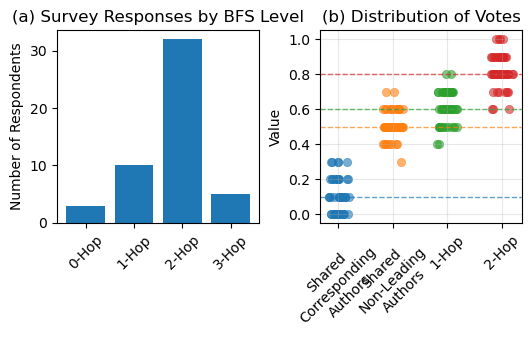

In [5]:
# Create figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 2.5))
plt.subplots_adjust(wspace=0.3, hspace=0)

distdf['x'] = distdf['hop'].astype('str') + '-Hop'
ax1.bar(distdf['x'], distdf['count'])
ax1.set_title('(a) Survey Responses by BFS Level')
ax1.set_ylabel('Number of Respondents')
ax1.set_xticklabels(distdf['x'], rotation=45)


# ========== LEFT: SCATTER PLOT ==========
x_labels = ['Shared\nCorresponding\nAuthors', 'Shared\nNon-Leading\nAuthors','1-Hop', '2-Hop']
udf[x_labels[0]] = udf['corresponding author']
udf[x_labels[1]] = udf['other']
udf[x_labels[2]] = udf['1-hop']
udf[x_labels[3]] = udf['2-hop']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
df = udf[x_labels]
for i, (col, color) in enumerate(zip(df.columns, colors)):
    # 增加抖动宽度
    jitter = np.random.uniform(-0.2, 0.2, size=len(df))
    x_positions = np.full(len(df), i) + jitter
    
    # 画散点
    ax2.scatter(x_positions, df[col], alpha=0.6, color=color, linewidth=0.5, label=col)
    
    # 添加均值线
    mean_val = round(df[col].mean()*10)/10
    ax2.axhline(y=mean_val, color=color, linestyle='--', alpha=0.7, linewidth=1)


ax2.set_ylabel('Value')
ax2.set_xticks(range(len(x_labels)))
ax2.set_xticklabels(x_labels, rotation=45)
ax2.set_title('(b) Distribution of Votes')
ax2.grid(True, alpha=0.3)
